# Data analysis: effect of prompt design on AI-based phishing email detection

This notebook processes the raw benchmark log produced by `src/benchmark.py`
(`data/raw/test_run.jsonl`), computes the statistics for the three research questions,
and exports the figures to `reports/figures/`.

**Reproducibility.** Run *Kernel -> Restart & Run All*. The notebook reads only the raw log and calls
the functions in `src/process_data.py` and `src/visualize.py`, so every number here is the same
number the command-line scripts produce. Random procedures (bootstrap) use seed 42.

**Structure:** 1. data ingestion and warm-up filtering, 2. statistical aggregation, 3. visualization and export.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

np.random.seed(42)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import process_data
import visualize

RAW_PATH = ROOT / "data" / "raw" / "test_run.jsonl"
METADATA_PATH = ROOT / "data" / "raw" / "run_metadata.json"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURE_DIR = ROOT / "reports" / "figures"

visualize.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("Project root:", ROOT)
print("Raw log:", RAW_PATH)

Project root: /Users/nurdauletorazgeldy/prompt-design-phishing-detection/prompt-design-phishing-detection
Raw log: /Users/nurdauletorazgeldy/prompt-design-phishing-detection/prompt-design-phishing-detection/data/raw/test_run.jsonl


## 0. Provenance of the run

Software versions, the Ollama version, the model digest and the dataset hash recorded by the benchmark (collection point M4).

In [2]:
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8")) if METADATA_PATH.exists() else {}
display(pd.Series(metadata, name="value").to_frame())
print({"numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__})

,value
python,3.12.16
platform,macOS-26.6.2-arm64-arm-64bit
requests,2.32.5
model,llama3.2:3b
temperature,0
seed,42
dataset_path,/Users/nurdauletorazgeldy/prompt-design-phishi...
dataset_sha256,1a4c780f136708b8ca065cad7318e69d1aa604833e788d...
ollama_version,0.40.3
model_digest,a80c4f17acd55265feec403c7aef86be0c25983ab279d8...


{'numpy': '2.0.2', 'pandas': '2.2.3', 'matplotlib': '3.9.4'}


## 1. Data ingestion and warm-up filtering

Each line of the log is one request. The first requests include loading the model into memory
(a "cold" spike), so they are stored as `phase = warmup` and discarded before any statistics.

In [3]:
raw = process_data.load_raw(RAW_PATH)
print(f"Records in raw log: {len(raw)}")
display(raw.groupby(["phase", "condition"]).size().unstack().rename_axis(None, axis=1))

Records in raw log: 806


,basic,structured
phase,,
eval,400,400
warmup,3,3


In [4]:
warmup = raw[raw["phase"] == "warmup"]
print("Warm-up latency (ms), discarded:")
display(warmup.groupby("condition")["latency_ms"].describe()[["count", "min", "50%", "max"]])

evaluation, n_warmup = process_data.split_warmup(raw)
conditions = [c for c in (process_data.BASELINE, process_data.PROPOSED) if c in set(evaluation["condition"])]
evaluation, n_incomplete = process_data.keep_complete_ids(evaluation, conditions)
print(f"Discarded warm-up records: {n_warmup}")
print(f"Emails dropped for missing a condition: {n_incomplete}")
print(f"Evaluation records kept: {len(evaluation)} ({evaluation['id'].nunique()} emails x {len(conditions)} conditions)")

Warm-up latency (ms), discarded:


,count,min,50%,max
condition,,,,
basic,3.0000,785.3550,1542.3220,8369.9290
structured,3.0000,943.9790,1143.4810,1543.6040


Discarded warm-up records: 6
Emails dropped for missing a condition: 0
Evaluation records kept: 800 (400 emails x 2 conditions)


In [5]:
# Sanity checks before any statistics.
assert not evaluation.duplicated(["condition", "id"]).any(), "duplicate (condition, id) pairs"
per_email = evaluation.drop_duplicates("id")
print("Class balance of evaluated emails:")
display(per_email["true_label"].value_counts().to_frame("emails"))
print("Invalid (unparseable) answers per condition:")
display((evaluation["predicted_label"] == "invalid").groupby(evaluation["condition"]).sum().to_frame("invalid"))
print("Email length in characters:")
display(per_email["email_chars"].describe().to_frame("chars").T)

Class balance of evaluated emails:


,emails
true_label,
phishing,200
legitimate,200


Invalid (unparseable) answers per condition:


,invalid
condition,
basic,0
structured,0


Email length in characters:


,count,mean,std,min,25%,50%,75%,max
chars,400.0000,1017.5550,697.3390,20.0000,412.7500,806.5000,1968.5000,2000.0000


## 2. Statistical aggregation

**Classification metrics** with Wilson 95% confidence intervals (proportions), and an **exact McNemar test**
for each research question (both prompts are evaluated on the same emails, so the data are paired).
Raw p-values are multiplied by 3 (Bonferroni) because three hypotheses are tested.

In [6]:
metrics = process_data.classification_metrics(evaluation, conditions)
display(metrics[["condition", "metric", "value", "ci_low", "ci_high", "k", "n", "invalid_answers"]])

,condition,metric,value,ci_low,ci_high,k,n,invalid_answers
0,basic,accuracy,0.8050,0.7633,0.8408,322,400,0
1,basic,phishing_detection_rate,0.6600,0.5919,0.7221,132,200,0
2,basic,false_positive_rate,0.0500,0.0274,0.0896,10,200,0
3,structured,accuracy,0.7575,0.7132,0.7969,303,400,0
4,structured,phishing_detection_rate,0.5300,0.4609,0.5980,106,200,0
5,structured,false_positive_rate,0.0150,0.0051,0.0432,3,200,0


In [7]:
tests = process_data.paired_tests(evaluation)
display(tests)
print("baseline_only = emails where the basic prompt was right (or made no false alarm) and structured was not;")
print("proposed_only = the reverse. Only these discordant emails carry information about a difference.")

,metric,n_emails,baseline_only,proposed_only,p_value,p_value_bonferroni
0,accuracy,400,30,11,0.0043,0.0130
1,phishing_detection_rate,200,29,3,0.0000,0.0000
2,false_positive_rate,200,8,1,0.0391,0.1172


baseline_only = emails where the basic prompt was right (or made no false alarm) and structured was not;
proposed_only = the reverse. Only these discordant emails carry information about a difference.


In [8]:
ALPHA = 0.05
names = {
    "accuracy": "RQ1 accuracy",
    "phishing_detection_rate": "RQ2 phishing detection rate",
    "false_positive_rate": "RQ3 false-positive rate",
}
for _, row in tests.iterrows():
    reject = row["p_value_bonferroni"] < ALPHA
    verdict = "H0 rejected" if reject else "H0 not rejected"
    print(f"{names[row['metric']]}: p = {row['p_value']:.4f}, Bonferroni p = {row['p_value_bonferroni']:.4f} "
          f"({row['baseline_only']} vs {row['proposed_only']} discordant emails) -> {verdict} at alpha = {ALPHA}")
print()
print("'H0 not rejected' means the data give no evidence of a difference; it does not prove the prompts are equal.")

RQ1 accuracy: p = 0.0043, Bonferroni p = 0.0130 (30 vs 11 discordant emails) -> H0 rejected at alpha = 0.05
RQ2 phishing detection rate: p = 0.0000, Bonferroni p = 0.0000 (29 vs 3 discordant emails) -> H0 rejected at alpha = 0.05
RQ3 false-positive rate: p = 0.0391, Bonferroni p = 0.1172 (8 vs 1 discordant emails) -> H0 not rejected at alpha = 0.05

'H0 not rejected' means the data give no evidence of a difference; it does not prove the prompts are equal.


In [9]:
latency = process_data.latency_statistics(evaluation, conditions)
display(latency.drop(columns="group"))

,condition,n,mean,sd,median,median_ci_low,median_ci_high,p25,p75,p95,p99
0,basic,400,1376.0818,890.6430,1109.2480,1026.1330,1259.3550,714.8835,1887.1525,2908.8870,3814.8053
1,structured,400,1419.6053,923.8868,1163.2550,1069.4670,1327.8050,749.2527,1885.6245,2954.0529,3628.2410


In [10]:
by_length = process_data.latency_by_length(evaluation, conditions)
display(by_length)

,condition,length_bin,n,chars_median,chars_min,chars_max,latency_median_ms,ci_low_ms,ci_high_ms
0,basic,0,80,232.5000,20,350,544.3870,518.0340,590.1040
1,basic,1,80,461.5000,352,606,785.0380,724.7320,870.5710
2,basic,2,80,806.5000,608,1061,1076.2775,973.7860,1189.0260
3,basic,3,160,2000.0000,1081,2000,2026.5605,1934.8950,2169.5470
4,structured,0,80,232.5000,20,350,547.0790,513.3750,597.0160
5,structured,1,80,461.5000,352,606,872.3510,768.2720,932.1910
6,structured,2,80,806.5000,608,1061,1076.2615,960.4380,1181.5140
7,structured,3,160,2000.0000,1081,2000,2043.0810,1925.2740,2178.2600


## 3. Visualization and export

All figures use axis labels with units, 95% confidence intervals, a colorblind-safe palette and distinct
markers / line styles. Each is saved as vector PDF and as PNG at 300 DPI in `reports/figures/`.

[PosixPath('/Users/nurdauletorazgeldy/prompt-design-phishing-detection/prompt-design-phishing-detection/reports/figures/fig1_latency_vs_load.pdf'),
 PosixPath('/Users/nurdauletorazgeldy/prompt-design-phishing-detection/prompt-design-phishing-detection/reports/figures/fig1_latency_vs_load.png')]

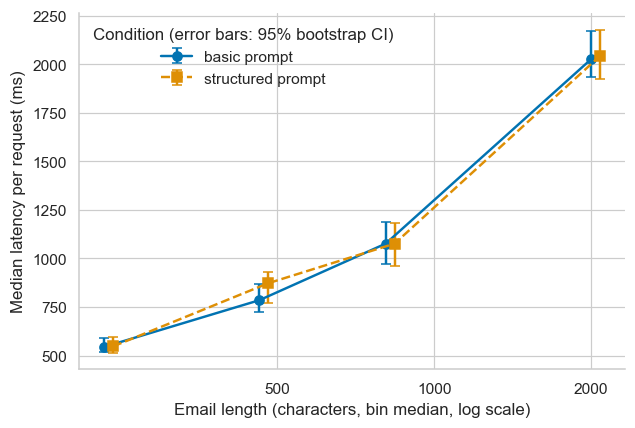

In [11]:
fig1 = visualize.figure_latency_vs_length(by_length, conditions)
display(visualize.save_figure(fig1, "fig1_latency_vs_load", FIGURE_DIR))
plt.show()

[PosixPath('/Users/nurdauletorazgeldy/prompt-design-phishing-detection/prompt-design-phishing-detection/reports/figures/fig2_distribution_boxplot.pdf'),
 PosixPath('/Users/nurdauletorazgeldy/prompt-design-phishing-detection/prompt-design-phishing-detection/reports/figures/fig2_distribution_boxplot.png')]

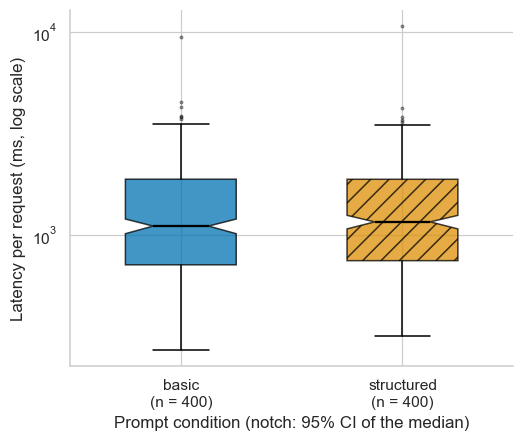

In [12]:
fig2 = visualize.figure_latency_boxplot(evaluation, conditions)
display(visualize.save_figure(fig2, "fig2_distribution_boxplot", FIGURE_DIR))
plt.show()

[PosixPath('/Users/nurdauletorazgeldy/prompt-design-phishing-detection/prompt-design-phishing-detection/reports/figures/fig3_metrics_with_ci.pdf'),
 PosixPath('/Users/nurdauletorazgeldy/prompt-design-phishing-detection/prompt-design-phishing-detection/reports/figures/fig3_metrics_with_ci.png')]

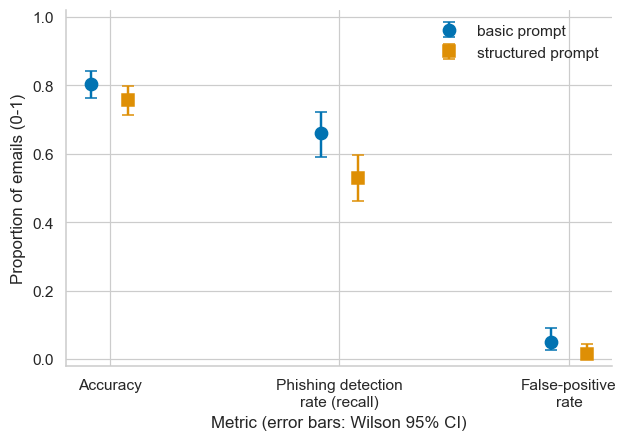

In [13]:
fig3 = visualize.figure_metrics_ci(metrics, conditions)
display(visualize.save_figure(fig3, "fig3_metrics_with_ci", FIGURE_DIR))
plt.show()

## 4. Export of aggregated tables

Writes `metrics_summary.csv`, `paired_tests.csv`, `latency_by_length.csv` and the README results table to `data/processed/`.

In [14]:
result = process_data.process(RAW_PATH, PROCESSED_DIR)
print(sorted(p.name for p in PROCESSED_DIR.iterdir()))
print()
print(result["table"])

['latency_by_length.csv', 'metrics_summary.csv', 'paired_tests.csv', 'results_table.md']

| Metric | basic (95% CI) | structured (95% CI) | McNemar p (Bonferroni) |
|---|---|---|---|
| Accuracy | 0.805 [0.763, 0.841] | 0.757 [0.713, 0.797] | 0.013 |
| Phishing detection rate (recall) | 0.660 [0.592, 0.722] | 0.530 [0.461, 0.598] | 0.000 |
| False-positive rate | 0.050 [0.027, 0.090] | 0.015 [0.005, 0.043] | 0.117 |

| Latency per request (ms) | n | Median (p25-p75) | p95 | p99 | Mean +/- SD |
|---|---|---|---|---|---|
| basic | 400 | 1109 (715-1887) | 2909 | 3815 | 1376 +/- 891 |
| structured | 400 | 1163 (749-1886) | 2954 | 3628 | 1420 +/- 924 |



## 5. How to read these results

- A confidence interval that is wide means the sample is too small to pin the value down.
- Recall (phishing detection rate) is the primary metric; accuracy and false-positive rate are guardrails against
  a prompt that catches more phishing only by blocking legitimate email.
- Latency is measured per request on one local machine, so absolute values do not transfer to other hardware;
  the comparison between the two prompts, measured in interleaved order on the same machine, does.
- The study uses one small model and one dataset; conclusions are limited accordingly.